# 서울시 무더위쉼터 최적 입지 분석

기존 성동구 AED 분석 코드를 **Python/Jupyter용으로 재구성**한 노트북입니다.

분석 흐름은 다음과 같습니다.

1. 서울시 행정동 경계 및 보행 네트워크 구축
2. 고령 유동인구 수요지, 기존 무더위쉼터, 신규 후보지 스냅
3. 네트워크 최단거리 계산
4. 기존 접근성 평가
5. **MCLP (`p=250` (예비))**
6. **p-median (`p=250` (예비))**
7. ** 형평성 MCLP ( p = 250) (예비) **
8. 세 모형의 커버율·인구가중 평균 접근거리·선정 입지 비교

> **중요:** `COVERAGE_DISTANCE_M`와 고령 유동인구 가중치 컬럼은 데이터센터에서 실제 데이터를 확인한 뒤 설정합니다.


In [1]:
# 필요한 패키지
# 설치가 필요한 경우 아래 주석을 해제해서 실행
# %pip install pandas numpy geopandas shapely pyproj networkx scipy matplotlib pulp openpyxl

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt

from shapely import wkt
from shapely.geometry import Point
from scipy.spatial import cKDTree

import pulp

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)


ModuleNotFoundError: No module named 'geopandas'

## 0. 분석 설정

아래 경로와 컬럼명만 실제 파일에 맞게 수정하면 됩니다.

- `P = 250`: 2025년 서울시 실제 추가 지정 규모를 준용한 시나리오
- `COVERAGE_DISTANCE_M`: MCLP 서비스 기준거리. 최종 분석 전 문헌·정책 근거를 통해 확정
- 수요 가중치: 데이터센터에서 확인한 60대 이상 유동인구 컬럼 사용


In [ ]:
# ============================================================
# 0. 경로 및 분석 설정
# ============================================================


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "2_데이터").exists())
BASE_DIR = ROOT / "2_데이터" / "서울_모형입력"  ## 저장소 기준 상대경로 (데이터 안심 구역에서는 그곳 경로로 변경)

NETWORK_PATH = BASE_DIR / "SeoulNetwork.csv"
ADM_GU_PATH = BASE_DIR / "SeoulBoundary.shp"
EXISTING_PATH = BASE_DIR / "SeoulCoolingCenter.csv"
CANDIDATE_PATH = BASE_DIR / "SeoulCandidateFacility.csv"


DEMAND_PATH = BASE_DIR / "Seoul_Test_Population.csv"  ## 이거는 가서 받아야 하는 데이터이므로 다른 데이터로 연습용으로 한번 실행해보자

ANALYSIS_CRS = 5179
GEOGRAPHIC_CRS = 4326

P = 250
COVERAGE_DISTANCE_M = None

SNAP_CHECK_THRESHOLD_M = 100

CLIP_NETWORK = True
NETWORK_BUFFER_M = 500

EXISTING_LON_COL = "경도"
EXISTING_LAT_COL = "위도"

CANDIDATE_LON_COL = "경도"
CANDIDATE_LAT_COL = "위도"

DEMAND_LON_COL = "경도"  # 이전 : 경도 
DEMAND_LAT_COL = "위도"  # 이전 : 위도

WEIGHT_COL = "population"
WEIGHT_COLS = []

# 예시:
# WEIGHT_COLS = ["남자60대이상유동인구", "여자60대이상유동인구"]


## 1. 보조 함수

In [6]:
def read_vector(path, crs_if_missing=None):
    gdf = gpd.read_file(path)
    if gdf.crs is None and crs_if_missing is not None:
        gdf = gdf.set_crs(crs_if_missing)
    return gdf


def read_point_csv(path, lon_col, lat_col, encoding="utf-8-sig"):
    try:
        df = pd.read_csv(path, encoding=encoding)
    except UnicodeDecodeError:
        df = pd.read_csv(path, encoding="cp949")

    df[lon_col] = pd.to_numeric(df[lon_col], errors="coerce")
    df[lat_col] = pd.to_numeric(df[lat_col], errors="coerce")
    df = df.dropna(subset=[lon_col, lat_col]).copy()

    return gpd.GeoDataFrame(
        df,
        geometry=gpd.points_from_xy(df[lon_col], df[lat_col]),
        crs=GEOGRAPHIC_CRS
    )


def ensure_points(gdf):
    out = gdf.copy()
    geom_types = set(out.geometry.geom_type.dropna().unique())
    if geom_types and geom_types.issubset({"Polygon", "MultiPolygon"}):
        out["geometry"] = out.representative_point()
    return out


def snap_points_to_nodes(points_gdf, nodes_gdf):
    pts = ensure_points(points_gdf).to_crs(nodes_gdf.crs).copy()

    node_xy = np.column_stack([
        nodes_gdf.geometry.x.to_numpy(),
        nodes_gdf.geometry.y.to_numpy()
    ])
    pt_xy = np.column_stack([
        pts.geometry.x.to_numpy(),
        pts.geometry.y.to_numpy()
    ])

    tree = cKDTree(node_xy)
    dist, idx = tree.query(pt_xy, k=1)

    pts["network_node"] = nodes_gdf.iloc[idx]["node_id"].to_numpy()
    pts["snap_distance_m"] = dist
    return pts


def print_snap_summary(gdf, label, threshold=100):
    s = gdf["snap_distance_m"]
    print(f"\\n[{label}]")
    print(s.describe())
    print(f"{threshold}m 초과: {(s > threshold).sum()}개")


def _endpoint_from_geometry(geom, start=True):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        coords = list(geom.coords)
        return Point(coords[0] if start else coords[-1])

    if geom.geom_type == "MultiLineString":
        parts = list(geom.geoms)
        target = parts[0] if start else parts[-1]
        coords = list(target.coords)
        return Point(coords[0] if start else coords[-1])

    return None


def make_weight(df, weight_col=None, weight_cols=None):
    out = df.copy()

    if weight_col is not None:
        if weight_col not in out.columns:
            raise KeyError(f"가중치 컬럼을 찾을 수 없습니다: {weight_col}")
        out["weight"] = pd.to_numeric(out[weight_col], errors="coerce")

    elif weight_cols:
        missing = [c for c in weight_cols if c not in out.columns]
        if missing:
            raise KeyError(f"가중치 컬럼을 찾을 수 없습니다: {missing}")
        out["weight"] = (
            out[weight_cols]
            .apply(pd.to_numeric, errors="coerce")
            .sum(axis=1, min_count=1)
        )

    else:
        print("수요 데이터 컬럼:")
        print(list(out.columns))
        raise ValueError(
            "WEIGHT_COL 또는 WEIGHT_COLS를 설정한 뒤 다시 실행하세요."
        )

    out["weight"] = out["weight"].fillna(0)
    return out


def weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    return np.average(values[mask], weights=weights[mask])


def weighted_coverage(covered, weights):
    covered = np.asarray(covered, dtype=bool)
    weights = np.asarray(weights, dtype=float)
    return weights[covered].sum() / weights.sum()


## 2. 행정구 경계 불러오기

In [ ]:
adm_GU = read_vector(ADM_GU_PATH).to_crs(ANALYSIS_CRS)

print(adm_GU.crs)
print("행정구 수:", len(adm_GU))
display(adm_GU.head())


EPSG:5179
행정구 수: 25


,BASE_DATE,SIGUNGU_CD,SIGUNGU_NM,geometry
0,20250630,11010,종로구,"POLYGON ((953683.828 1959209.871, 953665.283 1..."
1,20250630,11020,중구,"POLYGON ((957890.386 1952616.746, 957909.908 1..."
2,20250630,11030,용산구,"POLYGON ((953114.222 1950746.999, 953114.218 1..."
3,20250630,11040,성동구,"POLYGON ((959381.838 1952723.894, 959416.042 1..."
4,20250630,11050,광진구,"POLYGON ((964825.058 1952633.25, 964875.581 19..."


## 3. 서울시 보행 네트워크 구축

기존 AED 분석과 동일한 서울시 자치구별 도보 네트워크 CSV를 사용합니다.

- LINK: 시작노드, 종료노드, 링크 길이
- NODE: 노드 WKT
- 누락된 노드 좌표는 연결 LINK의 시작·끝 좌표로 복원
- 금천구 경계에 buffer를 두어 네트워크를 잘라 계산량을 줄임
- 가장 큰 연결요소만 사용


In [9]:
try:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="cp949",
        dtype=str,
        low_memory=False
    )
except UnicodeDecodeError:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="utf-8-sig",
        dtype=str,
        low_memory=False
    )

print("네트워크 원자료:", network_raw.shape)
display(network_raw.head())


네트워크 원자료: (491082, 23)


,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,읍면동코드,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,LINK,NaN,0,NaN,LINESTRING(126.96228683933481 37.5997378248954...,227523,1111,128414,128415,30.6370,1111000000,종로구,1111018600,신영동,0,0,0,0,0,0,0,0,2026-10-04 14:38:11.0
1,NODE,POINT(127.0099078298054 37.57668182537195),150733,0,NaN,0,NaN,NaN,NaN,NaN,1111000000,종로구,1111017400,창신동,NaN,NaN,NaN,NaN,0,0,NaN,NaN,2026-10-04 14:40:10.0
2,LINK,NaN,0,NaN,LINESTRING(126.99506871423829 37.5794324300485...,254542,1111,164485,164079,36.2740,1111000000,종로구,1111013000,와룡동,0,0,0,0,0,0,0,0,2026-10-04 14:38:29.0
3,LINK,NaN,0,NaN,LINESTRING(126.99336207048539 37.5902478559539...,15352,1111,135248,135225,14.0290,1111000000,종로구,1111017300,명륜3가,0,0,0,0,0,0,0,0,2026-10-04 14:36:13.0
4,LINK,NaN,0,NaN,LINESTRING(126.98204417605007 37.5802825342201...,56080,1111,133443,133444,34.8850,1111000000,종로구,1111014300,화동,0,0,0,0,0,0,0,0,2026-10-04 14:36:40.0


네트워크 원자료: (491082, 23)


,노드링크 유형,노드 WKT,노드 ID,노드 유형 코드,링크 WKT,링크 ID,링크 유형 코드,시작노드 ID,종료노드 ID,링크 길이,시군구코드,시군구명,읍면동코드,읍면동명,고가도로,지하철네트워크,교량,터널,육교,횡단보도,"공원,녹지",건물내,수집일자
0,LINK,NaN,0,NaN,LINESTRING(126.96228683933481 37.5997378248954...,227523,1111,128414,128415,30.6370,1111000000,종로구,1111018600,신영동,0,0,0,0,0,0,0,0,2026-10-04 14:38:11.0
1,NODE,POINT(127.0099078298054 37.57668182537195),150733,0,NaN,0,NaN,NaN,NaN,NaN,1111000000,종로구,1111017400,창신동,NaN,NaN,NaN,NaN,0,0,NaN,NaN,2026-10-04 14:40:10.0
2,LINK,NaN,0,NaN,LINESTRING(126.99506871423829 37.5794324300485...,254542,1111,164485,164079,36.2740,1111000000,종로구,1111013000,와룡동,0,0,0,0,0,0,0,0,2026-10-04 14:38:29.0
3,LINK,NaN,0,NaN,LINESTRING(126.99336207048539 37.5902478559539...,15352,1111,135248,135225,14.0290,1111000000,종로구,1111017300,명륜3가,0,0,0,0,0,0,0,0,2026-10-04 14:36:13.0
4,LINK,NaN,0,NaN,LINESTRING(126.98204417605007 37.5802825342201...,56080,1111,133443,133444,34.8850,1111000000,종로구,1111014300,화동,0,0,0,0,0,0,0,0,2026-10-04 14:36:40.0


전체 링크 수: 279016
시각화 가능한 링크 수: 279016
좌표계: EPSG:4326


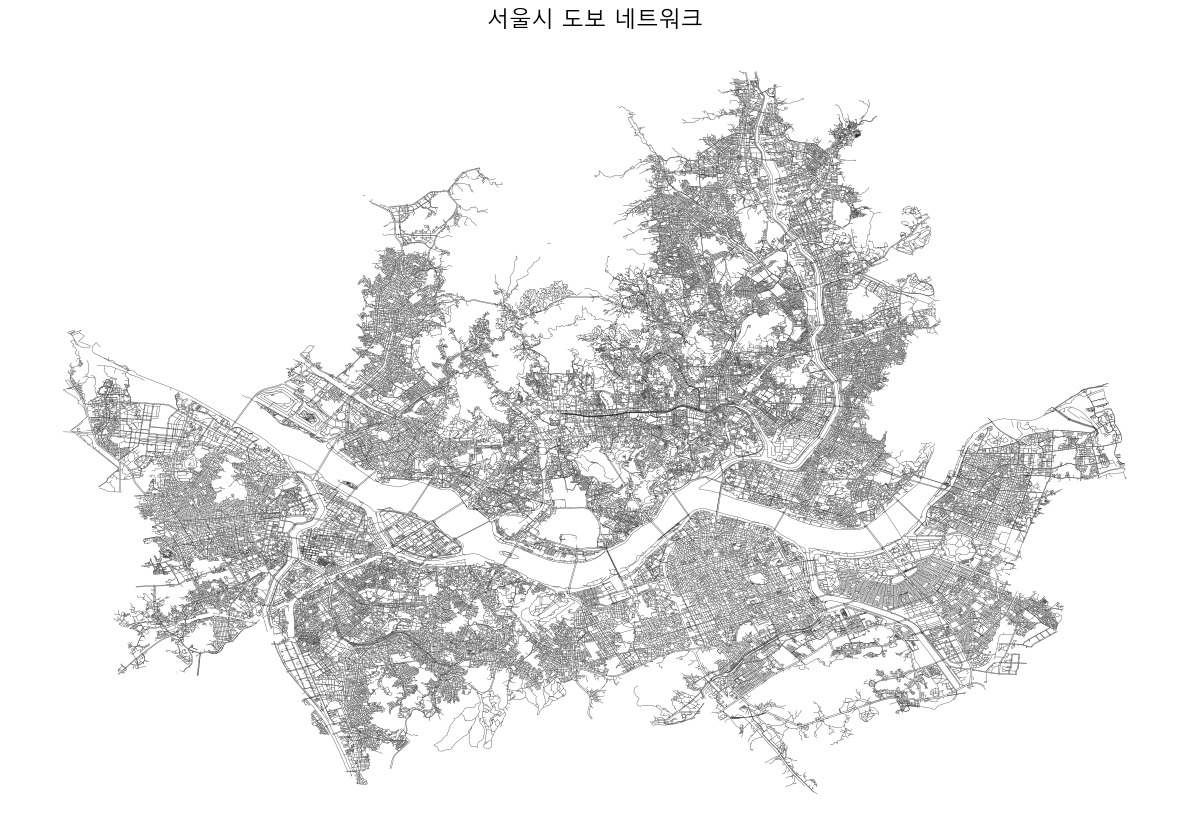

In [11]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import wkt
from matplotlib import font_manager


# 추가: Windows 한글 글꼴 설정
font_path = r"C:\Windows\Fonts\malgun.ttf"
font_name = font_manager.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

# 1. 네트워크 데이터 불러오기
try:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="cp949",
        dtype=str,
        low_memory=False
    )
except UnicodeDecodeError:
    network_raw = pd.read_csv(
        NETWORK_PATH,
        encoding="utf-8-sig",
        dtype=str,
        low_memory=False
    )

print("네트워크 원자료:", network_raw.shape)
display(network_raw.head())


# 2. LINK 데이터만 추출
network_links = network_raw.loc[
    (network_raw["노드링크 유형"] == "LINK")
    & network_raw["링크 WKT"].notna()
    & (network_raw["링크 WKT"].str.strip() != "")
].copy()


# 3. WKT 문자열을 공간 데이터로 변환
def parse_wkt(value):
    try:
        return wkt.loads(value)
    except Exception:
        return None


network_links["geometry"] = network_links["링크 WKT"].map(parse_wkt)
network_links = network_links.dropna(subset=["geometry"])


# 4. GeoDataFrame 생성
network_gdf = gpd.GeoDataFrame(
    network_links,
    geometry="geometry",
    crs="EPSG:4326"
)

print("전체 링크 수:", len(network_links))
print("시각화 가능한 링크 수:", len(network_gdf))
print("좌표계:", network_gdf.crs)


# 5. 도로 네트워크 시각화
fig, ax = plt.subplots(figsize=(12, 12))

network_gdf.plot(
    ax=ax,
    color="black",
    linewidth=0.25,
    alpha=0.8
)

ax.set_title("서울시 도보 네트워크", fontsize=16)
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
node_rows = network_raw.loc[
    (network_raw["노드링크 유형"] == "NODE")
    & network_raw["노드 WKT"].notna()
    & (network_raw["노드 WKT"] != "")
].copy()

node_rows["geometry"] = node_rows["노드 WKT"].map(wkt.loads)

node_gdf = gpd.GeoDataFrame(
    {
        "node_id": node_rows["노드 ID"].astype(str),
        "node_type": node_rows.get("노드 유형 코드"),
    },
    geometry=node_rows["geometry"],
    crs=GEOGRAPHIC_CRS
).drop_duplicates("node_id")

link_rows = network_raw.loc[
    (network_raw["노드링크 유형"] == "LINK")
    & network_raw["시작노드 ID"].notna()
    & network_raw["종료노드 ID"].notna()
    & network_raw["링크 길이"].notna()
].copy()

link_rows["from"] = link_rows["시작노드 ID"].astype(str)
link_rows["to"] = link_rows["종료노드 ID"].astype(str)
link_rows["length"] = pd.to_numeric(link_rows["링크 길이"], errors="coerce")
link_rows = link_rows.loc[
    np.isfinite(link_rows["length"]) & (link_rows["length"] > 0)
].copy()

graph_node_ids = set(link_rows["from"]) | set(link_rows["to"])
known_ids = set(node_gdf["node_id"])
missing_ids = graph_node_ids - known_ids

if missing_ids:
    recovery = link_rows.loc[
        link_rows["링크 WKT"].notna()
        & (
            link_rows["from"].isin(missing_ids)
            | link_rows["to"].isin(missing_ids)
        )
    ].copy()

    recovered = {}

    for _, row in recovery.iterrows():
        try:
            geom = wkt.loads(row["링크 WKT"])
        except Exception:
            continue

        if row["from"] in missing_ids and row["from"] not in recovered:
            recovered[row["from"]] = _endpoint_from_geometry(geom, start=True)

        if row["to"] in missing_ids and row["to"] not in recovered:
            recovered[row["to"]] = _endpoint_from_geometry(geom, start=False)

    rec_df = pd.DataFrame(
        [(nid, geom) for nid, geom in recovered.items() if geom is not None],
        columns=["node_id", "geometry"]
    )

    if len(rec_df):
        rec_gdf = gpd.GeoDataFrame(
            rec_df,
            geometry="geometry",
            crs=GEOGRAPHIC_CRS
        )
        rec_gdf["node_type"] = None
        node_gdf = pd.concat(
            [node_gdf, rec_gdf[["node_id", "node_type", "geometry"]]],
            ignore_index=True
        )
        node_gdf = gpd.GeoDataFrame(
            node_gdf, geometry="geometry", crs=GEOGRAPHIC_CRS
        ).drop_duplicates("node_id")

node_gdf = node_gdf.to_crs(ANALYSIS_CRS)

remaining_missing = graph_node_ids - set(node_gdf["node_id"])
print("좌표 미복원 네트워크 노드:", len(remaining_missing))


좌표 미복원 네트워크 노드: 0


In [ ]:
if CLIP_NETWORK:
    study_geom = adm_GU.geometry.union_all().buffer(NETWORK_BUFFER_M)
    keep_nodes = set(
        node_gdf.loc[node_gdf.geometry.intersects(study_geom), "node_id"]
    )

    link_use = link_rows.loc[
        link_rows["from"].isin(keep_nodes)
        & link_rows["to"].isin(keep_nodes)
    ].copy()
else:
    link_use = link_rows.copy()

G = nx.Graph()

for _, row in link_use.iterrows():
    u = str(row["from"])
    v = str(row["to"])
    length = float(row["length"])

    if G.has_edge(u, v):
        if length < G[u][v]["length"]:
            G[u][v]["length"] = length
    else:
        G.add_edge(u, v, length=length)

largest_cc = max(nx.connected_components(G), key=len)
G = G.subgraph(largest_cc).copy()

node_gdf = node_gdf.loc[
    node_gdf["node_id"].isin(G.nodes)
].drop_duplicates("node_id").copy()

print("그래프 노드:", G.number_of_nodes())
print("그래프 링크:", G.number_of_edges())
print("공간 노드:", len(node_gdf))


그래프 노드: 212986
그래프 링크: 276585
공간 노드: 212986


## 4. 기존 무더위쉼터·후보지·수요지 불러오기

현재 파일 형식에 맞게 경로와 좌표 컬럼명을 수정합니다.


In [14]:
existing = read_point_csv(
    EXISTING_PATH,
    EXISTING_LON_COL,
    EXISTING_LAT_COL
).to_crs(ANALYSIS_CRS)

candidate = read_point_csv(
    CANDIDATE_PATH,
    CANDIDATE_LON_COL,
    CANDIDATE_LAT_COL
).to_crs(ANALYSIS_CRS)

demand = read_point_csv(
    DEMAND_PATH,
    DEMAND_LON_COL,
    DEMAND_LAT_COL
).to_crs(ANALYSIS_CRS)

print("기존 무더위쉼터:", len(existing))
print("원 후보지:", len(candidate))
print("원 수요지:", len(demand))
print("수요지 CRS:", demand.crs)
print("수요지 좌표 범위:", demand.total_bounds)

기존 무더위쉼터: 4092
원 후보지: 1143
원 수요지: 824637
수요지 CRS: EPSG:5179
수요지 좌표 범위: [ 900050. 1900050.  999950. 1999950.]


### 4-1. 고령 유동인구 가중치 생성

In [15]:
demand = make_weight(
    demand,
    weight_col=WEIGHT_COL,
    weight_cols=WEIGHT_COLS
)

demand = demand.loc[
    np.isfinite(demand["weight"]) & (demand["weight"] > 0)
].copy()

print("양(+)의 가중치를 가진 수요격자:", len(demand))
print("총 고령 유동수요:", demand["weight"].sum())
display(demand.head())


양(+)의 가중치를 가진 수요격자: 185195
총 고령 유동수요: 25219497


,GRID_CD,geometry,population,경도,위도,weight
328,다사744004,POINT (974450 1900450),8,127.212459,37.102349,8
351,다사767004,POINT (976750 1900450),5,127.238343,37.102409,5
391,다사807004,POINT (980750 1900450),5,127.283359,37.102499,5
396,다사812004,POINT (981250 1900450),5,127.288986,37.102510,5
414,다사830004,POINT (983050 1900450),5,127.309243,37.102544,5


## 5. 네트워크 노드에 스냅

In [16]:
demand = snap_points_to_nodes(demand, node_gdf)
existing = snap_points_to_nodes(existing, node_gdf)
candidate = snap_points_to_nodes(candidate, node_gdf)

print_snap_summary(demand, "수요지", SNAP_CHECK_THRESHOLD_M)
print_snap_summary(existing, "기존 무더위쉼터", SNAP_CHECK_THRESHOLD_M)
print_snap_summary(candidate, "후보지", SNAP_CHECK_THRESHOLD_M)


\n[수요지]
count    185195.000000
mean      16045.203470
std       12279.444834
min           0.190703
25%        4650.727356
50%       15261.178771
75%       25877.866763
max       55228.239153
Name: snap_distance_m, dtype: float64
100m 초과: 154487개
\n[기존 무더위쉼터]
count    4092.000000
mean       26.036295
std        17.430018
min         0.671890
25%        14.824027
50%        22.043200
75%        32.260718
max       222.716859
Name: snap_distance_m, dtype: float64
100m 초과: 25개
\n[후보지]
count    1143.000000
mean       26.684032
std        17.760431
min         3.089134
25%        15.483816
50%        22.482575
75%        32.983242
max       227.136137
Name: snap_distance_m, dtype: float64
100m 초과: 6개


## 6. 분석용 수요지·기존시설·후보지 정리

- 동일 네트워크 노드에 연결된 수요격자는 가중치를 합산
- 동일 네트워크 노드의 후보지는 하나만 남김
- 기존 무더위쉼터와 같은 노드의 후보지는 제거


In [ ]:
graph_nodes = set(G.nodes)

existing_clean = existing.loc[
    existing["network_node"].isin(graph_nodes)
].copy()

existing_nodes = existing_clean["network_node"].drop_duplicates().tolist()

candidate_clean = (
    candidate.loc[candidate["network_node"].isin(graph_nodes)]
    .sort_values("snap_distance_m")
    .drop_duplicates("network_node", keep="first")
    .copy()
)

candidate_clean = candidate_clean.loc[
    ~candidate_clean["network_node"].isin(existing_nodes)
].copy()

candidate_clean = candidate_clean.reset_index(drop=True)
candidate_clean["candidate_id"] = [
    f"C{i:03d}" for i in range(1, len(candidate_clean) + 1)
]

# 서울시 자치구 경계의 컬럼명을 분석용 이름으로 정리
adm_gu = (
    adm_GU[["SIGUNGU_CD", "SIGUNGU_NM", "geometry"]]
    .rename(columns={
        "SIGUNGU_CD": "gu_code",
        "SIGUNGU_NM": "gu_name"
    })
    .to_crs(demand.crs)
    .copy()
)

# 수요점에 자치구 정보 결합
# 셀을 재실행해도 이전 지역 정보와 컬럼명이 충돌하지 않도록 제거
demand_with_gu = gpd.sjoin(
    demand.drop(
        columns=[
            "index_left", "index_right",
            "dong", "ADM_CD", "ADM_NM",
            "SIGUNGU_CD", "SIGUNGU_NM",
            "gu_code", "gu_name"
        ],
        errors="ignore"
    ),
    adm_gu,
    how="inner",
    predicate="within"
).drop(columns="index_right").copy()

# 같은 네트워크 노드라도 자치구가 다르면 별도 수요지로 유지
demand_model = (
    demand_with_gu.loc[
        demand_with_gu["network_node"].isin(graph_nodes)
    ]
    .groupby(["network_node", "gu_code"], as_index=False)
    .agg(
        gu_name=("gu_name", "first"),
        weight=("weight", "sum"),
        n_grid=("weight", "size")
    )
)

demand_model["demand_id"] = [
    f"D{i:04d}" for i in range(1, len(demand_model) + 1)
]

print("네트워크 노드 기준 통합 후 수요지:", len(demand_model))
print("경계자료의 자치구 수:", adm_gu["gu_code"].nunique())
print("분석 수요가 있는 자치구 수:", demand_model["gu_code"].nunique())
print("총 분석 수요 가중치:", demand_model["weight"].sum())


네트워크 노드 기준 통합 후 수요지: 30368
경계자료의 자치구 수: 25
분석 수요가 있는 자치구 수: 25
총 분석 수요 가중치: 9386974


## 7. 네트워크 최단거리 계산

- 기존 쉼터까지 거리는 `multi_source_dijkstra`로 한 번에 계산
- 후보지까지 거리는 후보지별 Dijkstra를 실행하여 행렬 생성


In [20]:
nearest_existing_dict = nx.multi_source_dijkstra_path_length(
    G,
    sources=existing_nodes,
    weight="length"
)

demand_nodes = demand_model["network_node"].tolist()

nearest_existing_m = np.array([
    nearest_existing_dict.get(n, np.inf)
    for n in demand_nodes
], dtype=float)

demand_model["nearest_existing_m"] = nearest_existing_m

print(demand_model["nearest_existing_m"].describe())
print(
    "기존 쉼터까지 인구가중 평균거리:",
    round(
        weighted_mean(
            demand_model["nearest_existing_m"],
            demand_model["weight"]
        ),
        2
    ),
    "m"
)


count    30368.000000
mean       262.354069
std        198.059790
min          0.000000
25%        135.264500
50%        224.367000
75%        340.805250
max       3211.886000
Name: nearest_existing_m, dtype: float64
기존 쉼터까지 인구가중 평균거리: 234.29 m


In [22]:
candidate_nodes = candidate_clean["network_node"].tolist()
demand_index_by_node = defaultdict(list)

for i, node in enumerate(demand_nodes):
    demand_index_by_node[node].append(i)

demand_node_set = set(demand_nodes)

demand_candidate_dist = np.full(
    (len(demand_model), len(candidate_clean)),
    np.inf,
    dtype=float
)

for j, source in enumerate(candidate_nodes):
    lengths = nx.single_source_dijkstra_path_length(
        G,
        source=source,
        weight="length"
    )

    for node in demand_node_set.intersection(lengths.keys()):
        d = lengths[node]
        for i in demand_index_by_node[node]:
            demand_candidate_dist[i, j] = d

    if (j + 1) % 50 == 0 or (j + 1) == len(candidate_nodes):
        print(f"후보지 거리계산: {j+1}/{len(candidate_nodes)}")

print("거리행렬 shape:", demand_candidate_dist.shape)


후보지 거리계산: 50/1064
후보지 거리계산: 100/1064
후보지 거리계산: 150/1064
후보지 거리계산: 200/1064
후보지 거리계산: 250/1064
후보지 거리계산: 300/1064
후보지 거리계산: 350/1064
후보지 거리계산: 400/1064
후보지 거리계산: 450/1064
후보지 거리계산: 500/1064
후보지 거리계산: 550/1064
후보지 거리계산: 600/1064
후보지 거리계산: 650/1064
후보지 거리계산: 700/1064
후보지 거리계산: 750/1064
후보지 거리계산: 800/1064
후보지 거리계산: 850/1064
후보지 거리계산: 900/1064
후보지 거리계산: 950/1064
후보지 거리계산: 1000/1064
후보지 거리계산: 1050/1064
후보지 거리계산: 1064/1064
거리행렬 shape: (30368, 1064)


## 8. 기존 무더위쉼터 접근성 평가

In [23]:
COVERAGE_DISTANCE_M = 219

if COVERAGE_DISTANCE_M is None:
    raise ValueError(
        "COVERAGE_DISTANCE_M를 먼저 설정하세요. "
        "예: COVERAGE_DISTANCE_M = 300"
    )

demand_model["existing_covered"] = (
    demand_model["nearest_existing_m"] <= COVERAGE_DISTANCE_M
).astype(int)

existing_coverage_rate = weighted_coverage(
    demand_model["existing_covered"].astype(bool),
    demand_model["weight"]
)

existing_mean_distance = weighted_mean(
    demand_model["nearest_existing_m"],
    demand_model["weight"]
)

print("커버 기준거리:", COVERAGE_DISTANCE_M, "m")
print("기존 고령 유동인구 커버율:", round(existing_coverage_rate * 100, 2), "%")
print("기존 인구가중 평균 접근거리:", round(existing_mean_distance, 2), "m")


커버 기준거리: 219 m
기존 고령 유동인구 커버율: 53.98 %
기존 인구가중 평균 접근거리: 234.29 m


## 9. MCLP

In [24]:
A = np.isfinite(demand_candidate_dist) & (
    demand_candidate_dist <= COVERAGE_DISTANCE_M
)

def solve_mclp(weights, existing_covered, coverage_matrix, p, msg=True):
    n_demand, n_candidate = coverage_matrix.shape

    if p > n_candidate:
        raise ValueError(f"p={p}가 후보지 수 {n_candidate}보다 큽니다.")

    model = pulp.LpProblem("MCLP", pulp.LpMaximize)

    x = {
        j: pulp.LpVariable(f"x_{j}", cat="Binary")
        for j in range(n_candidate)
    }
    y = {
        i: pulp.LpVariable(f"y_{i}", cat="Binary")
        for i in range(n_demand)
    }

    model += pulp.lpSum(weights[i] * y[i] for i in range(n_demand))
    model += pulp.lpSum(x[j] for j in range(n_candidate)) == p

    for i in range(n_demand):
        if existing_covered[i]:
            model += y[i] == 1
        else:
            js = np.flatnonzero(coverage_matrix[i])
            if len(js) == 0:
                model += y[i] == 0
            else:
                model += y[i] <= pulp.lpSum(x[j] for j in js)

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    selected = [
        j for j in range(n_candidate)
        if pulp.value(x[j]) is not None and pulp.value(x[j]) > 0.5
    ]

    return model, status, selected


weights = demand_model["weight"].to_numpy(float)
existing_covered = demand_model["existing_covered"].to_numpy(bool)

model_mclp, status_mclp, selected_mclp_idx = solve_mclp(
    weights=weights,
    existing_covered=existing_covered,
    coverage_matrix=A,
    p=P,
    msg=True
)

print("MCLP status:", status_mclp)
print("선정 후보지 수:", len(selected_mclp_idx))


MCLP status: Optimal
선정 후보지 수: 250


In [25]:
mclp_covered = existing_covered.copy()

if selected_mclp_idx:
    mclp_covered |= A[:, selected_mclp_idx].any(axis=1)

mclp_coverage_rate = weighted_coverage(
    mclp_covered,
    weights
)

mclp_nearest_new = (
    np.min(demand_candidate_dist[:, selected_mclp_idx], axis=1)
    if selected_mclp_idx
    else np.full(len(demand_model), np.inf)
)

mclp_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    mclp_nearest_new
)

mclp_mean_distance = weighted_mean(
    mclp_distance,
    weights
)

selected_mclp = candidate_clean.iloc[selected_mclp_idx].copy()
selected_mclp["model"] = "MCLP"

print("MCLP 커버율:", round(mclp_coverage_rate * 100, 2), "%")
print("MCLP 평균 접근거리:", round(mclp_mean_distance, 2), "m")

display(selected_mclp)


MCLP 커버율: 59.79 %
MCLP 평균 접근거리: 209.9 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
0,경로당,신반포16차아파트 경로당,서울특별시 서초구,1,서초구 잠원로 157,37.517279,127.010223,ArcGIS 지오코딩(주소 지점 일치),POINT (956718.441 1946555.919),95947,3.089134,C001,MCLP
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,MCLP
10,경로당,"사당신동아504동A, 신동아5차A",서울특별시 동작구,2,동작대로29길 118,37.490856,126.976269,ArcGIS 지오코딩(주소 지점 일치),POINT (953701.538 1943640.599),109818,5.584347,C011,MCLP
12,경로당,현대한강아파트경로당,서울특별시 용산구,1,서울특별시 용산구 이촌로34길 29,37.523161,126.958542,ArcGIS 지오코딩(주소 지점 일치),POINT (952155.053 1947233.58),63248,5.730361,C013,MCLP
14,경로당,서강해모로아파트 경로당,서울특별시 마포구 창전동,1,"토정로 167 (창전동, 서강해모로아파트)",37.546702,126.929534,ArcGIS 지오코딩(주소 지점 일치),POINT (949607.69 1949860.468),27546,5.962058,C015,MCLP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1052,경로당,LH강남아이파크아파트,서울특별시 강남구,1,강남구 자곡로 175,37.474417,127.101360,ArcGIS 지오코딩(주소 지점 일치),POINT (964752.044 1941762.653),201986,88.736656,C1053,MCLP
1054,경로당,마곡엠밸리6단지(아),서울특별시 강서구,1,강서구 마곡서1로 100,37.564355,126.822097,ArcGIS 지오코딩(주소 지점 일치),POINT (940131.222 1951882.002),214969,89.609436,C1055,MCLP
1058,경로당,마곡엠밸리7단지(아),서울특별시 강서구,1,강서구 마곡서로133,37.565135,126.822360,ArcGIS 지오코딩(주소 지점 일치),POINT (940155.056 1951968.417),215333,98.107436,C1059,MCLP
1059,경로당,상암카이저팰리스클래식경로당,서울특별시 마포구 상암동,1,"월드컵북로47길 37 (상암동, 상암카이저팰리스)",37.573433,126.891159,ArcGIS 지오코딩(주소 지점 일치),POINT (946237.009 1952847.433),140378,101.362586,C1060,MCLP


## 10. p-median

각 수요지에 대해 **현재 가장 가까운 기존 쉼터보다 더 가까운 후보지**만 assignment 대상으로 남겨 계산량을 줄입니다.


In [26]:
def solve_pmedian_with_existing(
    weights,
    nearest_existing,
    candidate_dist,
    p,
    msg=True
):
    n_demand, n_candidate = candidate_dist.shape

    if p > n_candidate:
        raise ValueError(f"p={p}가 후보지 수 {n_candidate}보다 큽니다.")

    better = (
        np.isfinite(candidate_dist)
        & (candidate_dist < nearest_existing[:, None])
    )

    demand_idx, candidate_idx = np.where(better)
    pair_distance = candidate_dist[demand_idx, candidate_idx]

    n_pair = len(demand_idx)

    pair_list = defaultdict(list)
    for k, i in enumerate(demand_idx):
        pair_list[int(i)].append(k)

    model = pulp.LpProblem("p_median", pulp.LpMinimize)

    x = {
        j: pulp.LpVariable(f"x_{j}", cat="Binary")
        for j in range(n_candidate)
    }

    u = {
        i: pulp.LpVariable(
            f"u_{i}",
            lowBound=0,
            upBound=1,
            cat="Continuous"
        )
        for i in range(n_demand)
    }

    v = {
        k: pulp.LpVariable(
            f"v_{k}",
            lowBound=0,
            upBound=1,
            cat="Continuous"
        )
        for k in range(n_pair)
    }

    model += (
        pulp.lpSum(
            weights[i] * nearest_existing[i] * u[i]
            for i in range(n_demand)
        )
        +
        pulp.lpSum(
            weights[demand_idx[k]]
            * pair_distance[k]
            * v[k]
            for k in range(n_pair)
        )
    )

    model += pulp.lpSum(x[j] for j in range(n_candidate)) == p

    for k in range(n_pair):
        model += v[k] <= x[int(candidate_idx[k])]

    for i in range(n_demand):
        ks = pair_list.get(i, [])
        if ks:
            model += u[i] + pulp.lpSum(v[k] for k in ks) == 1
        else:
            model += u[i] == 1

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    selected = [
        j for j in range(n_candidate)
        if pulp.value(x[j]) is not None and pulp.value(x[j]) > 0.5
    ]

    return model, status, selected


model_pmedian, status_pmedian, selected_pmedian_idx = solve_pmedian_with_existing(
    weights=weights,
    nearest_existing=demand_model["nearest_existing_m"].to_numpy(float),
    candidate_dist=demand_candidate_dist,
    p=P,
    msg=True
)

print("p-median status:", status_pmedian)
print("선정 후보지 수:", len(selected_pmedian_idx))


p-median status: Optimal
선정 후보지 수: 250


In [27]:
pmedian_nearest_new = (
    np.min(demand_candidate_dist[:, selected_pmedian_idx], axis=1)
    if selected_pmedian_idx
    else np.full(len(demand_model), np.inf)
)

pmedian_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    pmedian_nearest_new
)

pmedian_mean_distance = weighted_mean(
    pmedian_distance,
    weights
)

pmedian_covered = pmedian_distance <= COVERAGE_DISTANCE_M
pmedian_coverage_rate = weighted_coverage(
    pmedian_covered,
    weights
)

selected_pmedian = candidate_clean.iloc[selected_pmedian_idx].copy()
selected_pmedian["model"] = "p-median"

print("p-median 커버율:", round(pmedian_coverage_rate * 100, 2), "%")
print("p-median 평균 접근거리:", round(pmedian_mean_distance, 2), "m")

display(selected_pmedian)


p-median 커버율: 59.07 %
p-median 평균 접근거리: 206.86 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,p-median
6,경로당,서광(아),서울특별시 강서구,1,강서구 양천로 27길 129,37.579619,126.819605,ArcGIS 지오코딩(주소 지점 일치),POINT (939923.42 1953577.073),159730,5.081077,C007,p-median
7,경로당,신계경로당,서울특별시 용산구,1,서울특별시 용산구 원효로 216,37.534523,126.967158,ArcGIS 지오코딩(주소 지점 일치),POINT (952923.607 1948489.749),177065,5.257596,C008,p-median
12,경로당,현대한강아파트경로당,서울특별시 용산구,1,서울특별시 용산구 이촌로34길 29,37.523161,126.958542,ArcGIS 지오코딩(주소 지점 일치),POINT (952155.053 1947233.58),63248,5.730361,C013,p-median
14,경로당,서강해모로아파트 경로당,서울특별시 마포구 창전동,1,"토정로 167 (창전동, 서강해모로아파트)",37.546702,126.929534,ArcGIS 지오코딩(주소 지점 일치),POINT (949607.69 1949860.468),27546,5.962058,C015,p-median
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1054,경로당,마곡엠밸리6단지(아),서울특별시 강서구,1,강서구 마곡서1로 100,37.564355,126.822097,ArcGIS 지오코딩(주소 지점 일치),POINT (940131.222 1951882.002),214969,89.609436,C1055,p-median
1057,경로당,공덕자이(아)경로당,서울특별시 마포구,1,마포대로24길 16,37.552791,126.958931,ArcGIS 지오코딩(주소 지점 일치),POINT (952208.386 1950520.716),69044,93.957648,C1058,p-median
1058,경로당,마곡엠밸리7단지(아),서울특별시 강서구,1,강서구 마곡서로133,37.565135,126.822360,ArcGIS 지오코딩(주소 지점 일치),POINT (940155.056 1951968.417),215333,98.107436,C1059,p-median
1059,경로당,상암카이저팰리스클래식경로당,서울특별시 마포구 상암동,1,"월드컵북로47길 37 (상암동, 상암카이저팰리스)",37.573433,126.891159,ArcGIS 지오코딩(주소 지점 일치),POINT (946237.009 1952847.433),140378,101.362586,C1060,p-median


## 11. 형평성 MCLP

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix, vstack, csr_matrix

In [ ]:
# ============================================================
# 형평성 MCLP
# 기존 MCLP와 동일한 수요, 거리, 커버 기준, 후보지 수 사용
# ============================================================

ETA = 0.95


def solve_equity_mclp(
    weights,
    gus,
    existing_covered,
    coverage_matrix,
    p,
    basic_optimum_people,
    eta=0.95,
    msg=True
):
    weights = np.asarray(weights, dtype=float)
    gus = np.asarray(gus)
    existing_covered = np.asarray(existing_covered, dtype=bool)
    coverage_matrix = np.asarray(coverage_matrix, dtype=bool)

    n_demand, n_candidate = coverage_matrix.shape

    # -----------------------------
    # 입력값 검증
    # -----------------------------
    if len(weights) != n_demand:
        raise ValueError("weights 길이와 수요지 수가 다릅니다.")

    if len(gus) != n_demand:
        raise ValueError("gus 길이와 수요지 수가 다릅니다.")

    if len(existing_covered) != n_demand:
        raise ValueError(
            "existing_covered 길이와 수요지 수가 다릅니다."
        )

    if pd.isna(gus).any():
        raise ValueError("행정동 정보에 결측값이 있습니다.")

    if not np.isfinite(weights).all() or (weights < 0).any():
        raise ValueError(
            "weights는 유한한 음이 아닌 값이어야 합니다."
        )

    if weights.sum() <= 0:
        raise ValueError("전체 수요 가중치는 0보다 커야 합니다.")

    if not isinstance(p, (int, np.integer)) or not 0 <= p <= n_candidate:
        raise ValueError(
            f"p는 0 이상 후보지 수 {n_candidate} 이하의 정수여야 합니다."
        )

    if not np.isfinite(eta) or not 0 < eta <= 1:
        raise ValueError("eta는 0보다 크고 1 이하여야 합니다.")

    if (
        not np.isfinite(basic_optimum_people)
        or basic_optimum_people < 0
    ):
        raise ValueError(
            "basic_optimum_people 값이 올바르지 않습니다."
        )

    # -----------------------------
    # 형평성 MCLP 모형
    # -----------------------------
    model = pulp.LpProblem(
        "Equity_MCLP",
        pulp.LpMaximize
    )

    # 후보지 선택 여부
    x = {
        j: pulp.LpVariable(
            f"equity_x_{j}",
            cat="Binary"
        )
        for j in range(n_candidate)
    }

    # 수요지 커버 여부
    y = {
        i: pulp.LpVariable(
            f"equity_y_{i}",
            cat="Binary"
        )
        for i in range(n_demand)
    }

    # 모든 행정구이 보장받는 최소 커버율
    q = pulp.LpVariable(
        "minimum_gu_coverage",
        lowBound=0,
        upBound=1,
        cat="Continuous"
    )

    # 목적함수: 최저 행정동 커버율 최대화
    model += q

    # 기존 MCLP와 동일하게 정확히 p개 후보지 선택
    model += (
        pulp.lpSum(x[j] for j in range(n_candidate))
        == p
    )

    # 수요지 커버 여부 결정
    for i in range(n_demand):
        if existing_covered[i]:
            # 기존 시설이 커버하는 수요지
            model += y[i] == 1

        else:
            js = np.flatnonzero(coverage_matrix[i])

            if len(js) == 0:
                # 기존 및 신규 시설 어느 쪽에서도 커버 불가능
                model += y[i] == 0

            else:
                # 선택된 커버 후보지가 없으면 y[i] = 0
                model += (
                    y[i]
                    <= pulp.lpSum(x[int(j)] for j in js)
                )

                # 하나 이상의 커버 후보지가 선택되면 y[i] = 1
                for j in js:
                    model += y[i] >= x[int(j)]

    # 기본 MCLP 최대 커버 인구의 eta 이상 유지
    model += (
        pulp.lpSum(
            weights[i] * y[i]
            for i in range(n_demand)
        )
        >= eta * basic_optimum_people
    )

    # 자치구별 커버율이 q 이상이어야 함
    for gu in pd.unique(gus):
        idx = np.flatnonzero(gus == gu)
        gu_population = float(weights[idx].sum())

        if gu_population <= 0:
            continue

        model += (
            pulp.lpSum(
                weights[int(i)] * y[int(i)]
                for i in idx
            )
            >= q * gu_population
    )

    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]

    if status != "Optimal":
        raise RuntimeError(
            f"형평성 MCLP 최적해를 찾지 못했습니다: {status}"
        )

    selected = [
        j for j in range(n_candidate)
        if (
            pulp.value(x[j]) is not None
            and pulp.value(x[j]) > 0.5
        )
    ]

    minimum_gu_coverage = float(pulp.value(q))

    return model, status, selected, minimum_gu_coverage


# ------------------------------------------------------------
# 기존 MCLP가 달성한 최대 커버 인구 계산
# ------------------------------------------------------------

if status_mclp != "Optimal":
    raise RuntimeError(
        "기존 MCLP가 Optimal 상태가 아니므로 "
        "형평성 MCLP와 비교할 수 없습니다."
    )

basic_covered_for_equity = existing_covered.copy()

if selected_mclp_idx:
    basic_covered_for_equity |= (
        A[:, selected_mclp_idx].any(axis=1)
    )

basic_optimum_people = float(
    weights[basic_covered_for_equity].sum()
)

# ------------------------------------------------------------
# 형평성 MCLP 실행
# ------------------------------------------------------------

model_equity_mclp, status_equity_mclp, selected_equity_mclp_idx, equity_q = (
    solve_equity_mclp(
        weights=weights,
        gus=demand_model["gu_code"].to_numpy(),
        existing_covered=existing_covered,
        coverage_matrix=A,
        p=P,
        basic_optimum_people=basic_optimum_people,
        eta=ETA,
        msg=True
    )
)

print("형평성 MCLP status:", status_equity_mclp)
print("선정 후보지 수:", len(selected_equity_mclp_idx))

형평성 MCLP status: Optimal
선정 후보지 수: 250


In [31]:
equity_mclp_covered = existing_covered.copy()

if selected_equity_mclp_idx:
    equity_mclp_covered |= (
        A[:, selected_equity_mclp_idx].any(axis=1)
    )

equity_mclp_coverage_rate = weighted_coverage(
    equity_mclp_covered,
    weights
)

equity_mclp_nearest_new = (
    np.min(
        demand_candidate_dist[
            :,
            selected_equity_mclp_idx
        ],
        axis=1
    )
    if selected_equity_mclp_idx
    else np.full(len(demand_model), np.inf)
)

equity_mclp_distance = np.minimum(
    demand_model["nearest_existing_m"].to_numpy(float),
    equity_mclp_nearest_new
)

equity_mclp_mean_distance = weighted_mean(
    equity_mclp_distance,
    weights
)

selected_equity_mclp = (
    candidate_clean
    .iloc[selected_equity_mclp_idx]
    .copy()
)

selected_equity_mclp["model"] = "형평성 MCLP"

# 효율성 유지 제약 사후 검증
equity_covered_people = float(
    weights[equity_mclp_covered].sum()
)

tolerance = 1e-5 * max(1.0, basic_optimum_people)

if (
    equity_covered_people + tolerance
    < ETA * basic_optimum_people
):
    raise RuntimeError(
        "형평성 MCLP 결과가 eta 효율성 제약을 위반했습니다."
    )

print(
    "형평성 MCLP 커버율:",
    round(equity_mclp_coverage_rate * 100, 2),
    "%"
)

print(
    "형평성 MCLP 평균 접근거리:",
    round(equity_mclp_mean_distance, 2),
    "m"
)

display(selected_equity_mclp)

형평성 MCLP 커버율: 58.22 %
형평성 MCLP 평균 접근거리: 212.4 m


,시설유형,시설명,시구동,시설수,상세주소,위도,경도,좌표출처,geometry,network_node,snap_distance_m,candidate_id,model
0,경로당,신반포16차아파트 경로당,서울특별시 서초구,1,서초구 잠원로 157,37.517279,127.010223,ArcGIS 지오코딩(주소 지점 일치),POINT (956718.441 1946555.919),95947,3.089134,C001,형평성 MCLP
1,경로당,(장안동)현대아파트경로당,서울특별시 동대문구 장안동,1,서울특별시 동대문구 한천로 224 (장안동),37.580826,127.068513,ArcGIS 지오코딩(주소 지점 일치),POINT (961901.887 1953580.947),3703,3.097204,C002,형평성 MCLP
4,경로당,동현,서울특별시 강남구,1,강남구 언주로 146길 18,37.518643,127.036858,ArcGIS 지오코딩(주소 지점 일치),POINT (959072.952 1946695.381),130691,4.123171,C005,형평성 MCLP
11,경로당,한강아파트 경로당,서울특별시 서초구,1,서초구 잠원로213-10,37.521369,127.015293,ArcGIS 지오코딩(주소 지점 일치),POINT (957168.756 1947007.371),110401,5.723923,C012,형평성 MCLP
12,경로당,현대한강아파트경로당,서울특별시 용산구,1,서울특별시 용산구 이촌로34길 29,37.523161,126.958542,ArcGIS 지오코딩(주소 지점 일치),POINT (952155.053 1947233.58),63248,5.730361,C013,형평성 MCLP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1050,경로당,래미안대치팰리스2단지아파트,서울특별시 강남구,1,강남구 삼성로51길 35,37.495564,127.061403,ArcGIS 지오코딩(주소 지점 일치),POINT (961230.03 1944124.485),11163,85.935438,C1051,형평성 MCLP
1052,경로당,LH강남아이파크아파트,서울특별시 강남구,1,강남구 자곡로 175,37.474417,127.101360,ArcGIS 지오코딩(주소 지점 일치),POINT (964752.044 1941762.653),201986,88.736656,C1053,형평성 MCLP
1059,경로당,상암카이저팰리스클래식경로당,서울특별시 마포구 상암동,1,"월드컵북로47길 37 (상암동, 상암카이저팰리스)",37.573433,126.891159,ArcGIS 지오코딩(주소 지점 일치),POINT (946237.009 1952847.433),140378,101.362586,C1060,형평성 MCLP
1060,경로당,롯데캐슬갤럭시1차 경로당,서울특별시 서초구,1,서초구 잠원로14길 3,37.519720,127.017017,ArcGIS 지오코딩(주소 지점 일치),POINT (957320.168 1946823.663),110383,110.429303,C1061,형평성 MCLP


## 11. MCLP vs 형평성 MCLP vs p-median 

In [ ]:
def calculate_min_gu_coverage_pct(
    covered,
    weights,
    gus
):
    covered = np.asarray(covered, dtype=bool)
    weights = np.asarray(weights, dtype=float)
    gus = np.asarray(gus)

    coverage_df = pd.DataFrame({
        "gu": gus,
        "population": weights,
        "covered_population": weights * covered.astype(int)
    })

    gu_coverage = (
        coverage_df
        .groupby("gu", as_index=False)
        .agg(
            population=("population", "sum"),
            covered_population=("covered_population", "sum")
        )
    )

    gu_coverage["coverage_rate"] = (
        gu_coverage["covered_population"]
        / gu_coverage["population"]
    )

    return gu_coverage["coverage_rate"].min() * 100


# 행정구 정보
gus = demand_model["gu_code"].to_numpy()

# 모델별 최저 행정구 커버율
existing_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        existing_covered,
        weights,
        gus
    )
)

mclp_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        mclp_covered,
        weights,
        gus
    )
)

equity_mclp_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        equity_mclp_covered,
        weights,
        gus
    )
)

pmedian_min_gu_coverage_pct = (
    calculate_min_gu_coverage_pct(
        pmedian_covered,
        weights,
        gus
    )
)


# 모델 비교표
comparison = pd.DataFrame({
    "model": [
        "기존",
        "MCLP",
        "형평성 MCLP",
        "p-median"
    ],
    "coverage_rate_pct": [
        existing_coverage_rate * 100,
        mclp_coverage_rate * 100,
        equity_mclp_coverage_rate * 100,
        pmedian_coverage_rate * 100
    ],
    "weighted_mean_distance_m": [
        existing_mean_distance,
        mclp_mean_distance,
        equity_mclp_mean_distance,
        pmedian_mean_distance
    ],
    "min_gu_coverage_rate_pct": [
        existing_min_gu_coverage_pct,
        mclp_min_gu_coverage_pct,
        equity_mclp_min_gu_coverage_pct,
        pmedian_min_gu_coverage_pct
    ]
}).round(2)

display(comparison)

,model,coverage_rate_pct,weighted_mean_distance_m,min_gu_coverage_rate_pct
0,기존,53.98,234.29,20.75
1,MCLP,59.79,209.90,41.04
2,형평성 MCLP,58.22,212.40,51.53
3,p-median,59.07,206.86,42.10


## 12. 선정 입지 지도

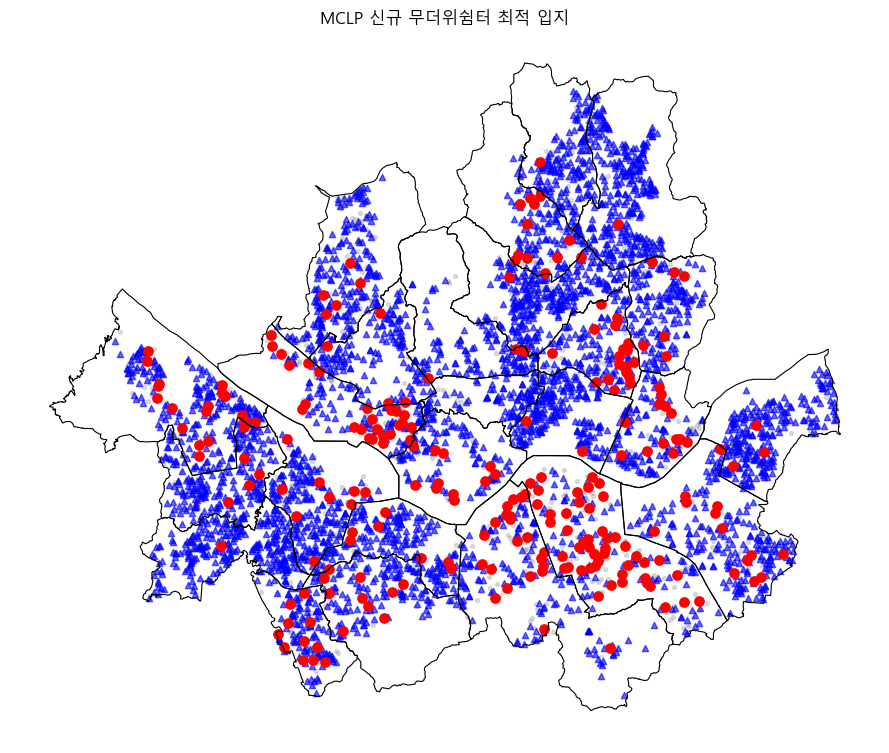

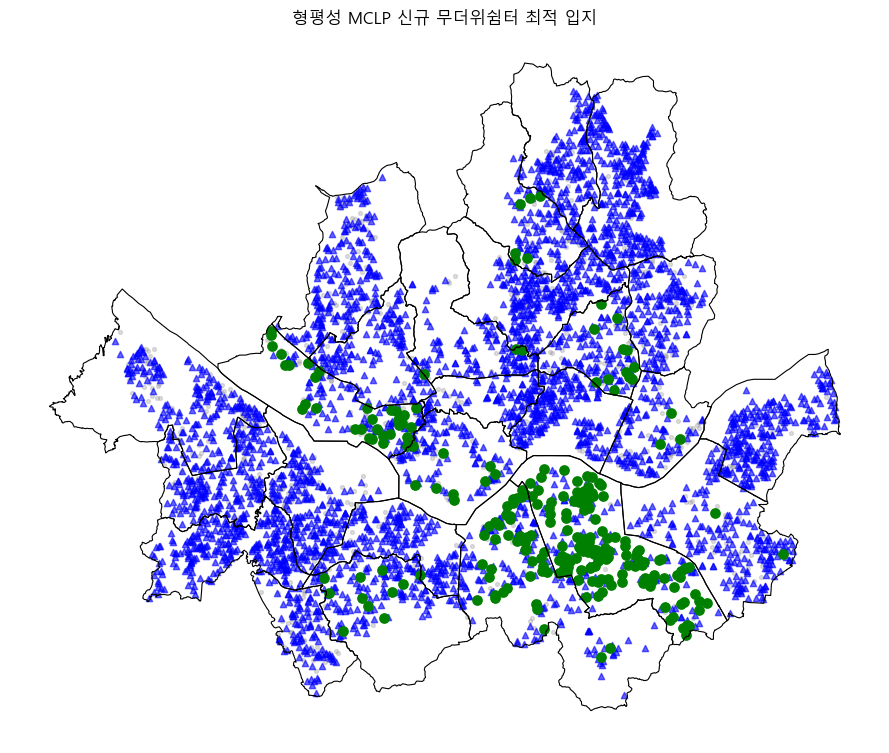

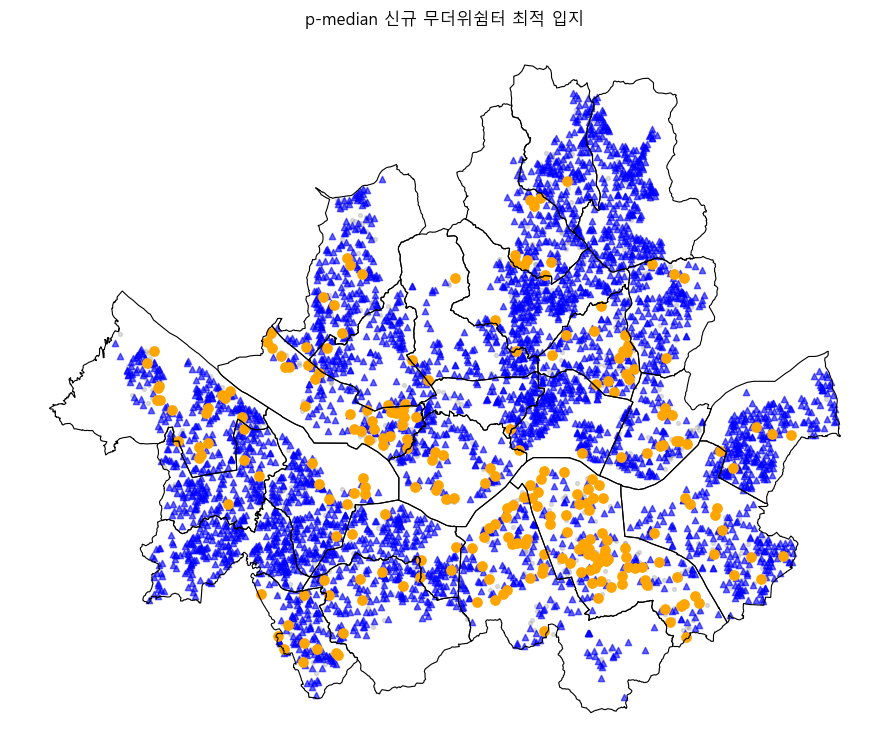

In [ ]:
from matplotlib import font_manager

# Windows 한글 글꼴 설정
font_path = r"C:\Windows\Fonts\malgun.ttf"
font_name = font_manager.FontProperties(
    fname=font_path
).get_name()

plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False


# ============================================================
# 1. 기본 MCLP 결과
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25
)

existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)

if len(selected_mclp):
    selected_mclp.plot(
        ax=ax,
        color="red",
        marker="o",
        markersize=45
    )

ax.set_title("MCLP 신규 무더위쉼터 최적 입지")
ax.set_axis_off()

plt.tight_layout()
plt.show()


# ============================================================
# 2. 형평성 MCLP 결과
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25
)

existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)

if len(selected_equity_mclp):
    selected_equity_mclp.plot(
        ax=ax,
        color="green",
        marker="o",
        markersize=45
    )

ax.set_title("형평성 MCLP 신규 무더위쉼터 최적 입지")
ax.set_axis_off()

plt.tight_layout()
plt.show()


# ============================================================
# 3. p-median 결과
# ============================================================

fig, ax = plt.subplots(figsize=(9, 9))

adm_GU.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

candidate_clean.plot(
    ax=ax,
    color="gray",
    markersize=8,
    alpha=0.25
)

existing_clean.plot(
    ax=ax,
    color="blue",
    marker="^",
    markersize=20,
    alpha=0.6
)

if len(selected_pmedian):
    selected_pmedian.plot(
        ax=ax,
        color="orange",
        marker="o",
        markersize=45
    )

ax.set_title("p-median 신규 무더위쉼터 최적 입지")
ax.set_axis_off()

plt.tight_layout()
plt.show()

1. 시각화를 많이 해놨으면 좋겠는데 그게 조금 부족함 (ex : EDA라고 부를만한 게 딱히 없음)
2. 형평성 MCLP 코드 부재 - 용진
3. 평가 지표 없음 
- 모델 3개마다의 장점 존재 (목적함수)
- 각 모델의 유리한 평가 지표 ? 를 보여줬음 
- 객관적 평가 지표를 못 찾았음
4. 서울 전체 확장 ? --> p를 확정적으로 지어야 함 (계산량 엄청 많음)
** p를 찾자 (전년도에 얼마나 지었는지 참고하는게 좋아보임) 

해야 할 것 

1. 코드 합치기 (안심구역에서랑 우리 로컬에서 돌린거랑 합쳐야 함)
- 시각화 추가 
2. 평가 지표 코드 짜기 + 형평성 MCLP - 용진 
3. 서울시로 확장한다고 가정하면 / 후보지 '전처리' 사전 작업 필요 - 동근, 광일
- ** 서울시로 확장하면 p를 명확하게 정해야 함 
- 데이터는 용진이 보내줌 

왜 60대 이상을 목표로 했는지 필요성에 대한 언급 
- 무더위 쉼터 중 경로당 비율이 가장 높고 경로당 같은 경우 자주 이용하는 나이대가 60대 이상임을 보여주면 좋지 않을까